In [2]:

# Importing the pandas library for data manipulation and analysis
import pandas as pd

# Importing Plotly Express for high-level, easy-to-use interactive visualizations
import plotly.express as px

# Importing Plotly Graph Objects for more fine-grained control over visualizations
import plotly.graph_objects as go

# Importing NumPy for numerical operations and array manipulation
import numpy as np

# Importing Seaborn for statistical data visualization (optional but can complement Plotly)
import seaborn as sns

import matplotlib.pyplot as plt



In [3]:
# read the data
df = pd.read_csv("../data/amz_uk_processed_data.csv")
df.head()
df.shape
df.info()
df.nunique()


<class 'pandas.DataFrame'>
RangeIndex: 2222742 entries, 0 to 2222741
Data columns (total 10 columns):
 #   Column             Dtype  
---  ------             -----  
 0   asin               str    
 1   title              str    
 2   imgUrl             str    
 3   productURL         str    
 4   stars              float64
 5   reviews            int64  
 6   price              float64
 7   isBestSeller       bool   
 8   boughtInLastMonth  int64  
 9   categoryName       str    
dtypes: bool(1), float64(2), int64(2), str(5)
memory usage: 679.1 MB


asin                 2222742
title                2073245
imgUrl               1770232
productURL           2222742
stars                     42
reviews                17216
price                  82687
isBestSeller               2
boughtInLastMonth         25
categoryName             296
dtype: int64

Frequency Tables:

    Generate a frequency table for the product category.
    Which are the top 5 most listed product categories?

In [4]:

#    Generate a frequency table for the product category.
category_counts = df["categoryName"].value_counts()
#    Which are the top 5 most listed product categories?
top5_cats = category_counts[:5]
print("The top 5 most listed categories are:\n",top5_cats.index)

The top 5 most listed categories are:
 Index(['Sports & Outdoors', 'Skin Care', 'Fragrances', 'Make-up',
       'Manicure & Pedicure Products'],
      dtype='str', name='categoryName')


Visualizations:

    Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
    
    For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

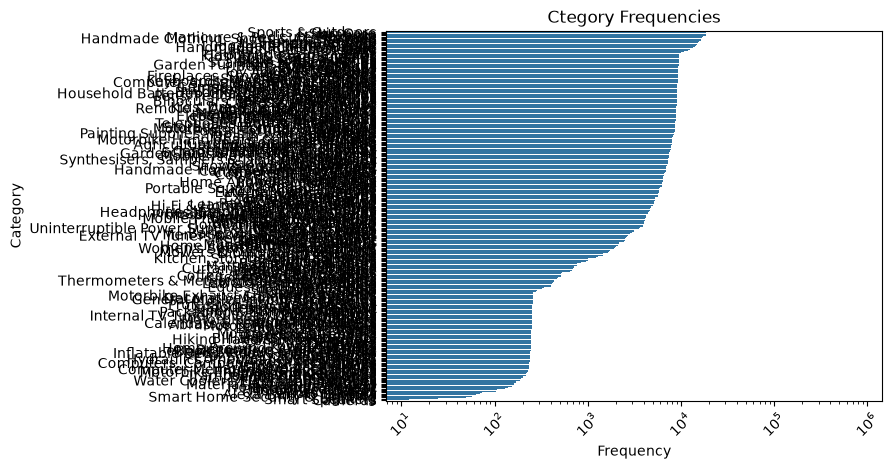

In [5]:

sns.barplot(y=category_counts.index, x=category_counts.values)
plt.ylabel("Category")
plt.xlabel("Frequency")
plt.title("Ctegory Frequencies")
plt.xscale("log")  # for better visualisation
plt.xticks(rotation=45)
plt.show()



Too many categories to be seem. Used logscale for better visualisation.
Without logscale, we see that there is a category that has much higher counts than the rest. Lets try with only the top 5:

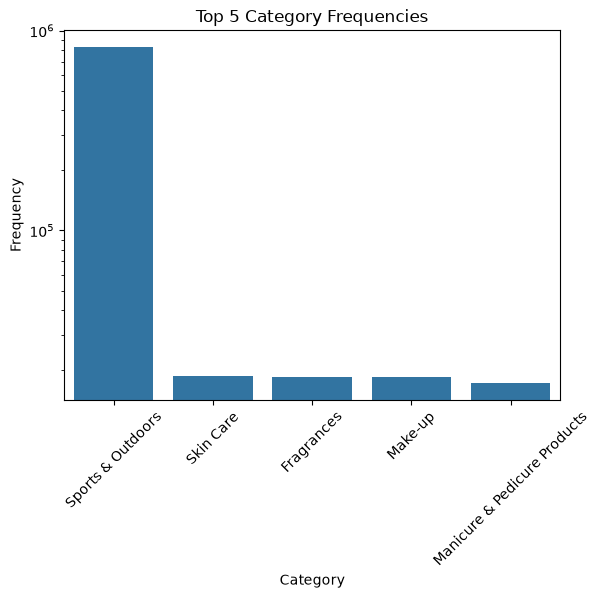

In [6]:
sns.barplot(x=top5_cats.index, y=top5_cats.values)
plt.xlabel("Category")
plt.ylabel("Frequency")
plt.title("Top 5 Category Frequencies")
plt.xticks(rotation=45)
plt.yscale("log")
plt.show()

Now a top5 pie chart:
More than 90% of the products are in category "Sport and Outdoors"

In [7]:
fig = px.pie(
    values=top5_cats.values,
    names=top5_cats.index,
    title="Top 5 Categories",
    hole=0  # 0 = pie chart, >0 = doughnut chart
)

fig.show()


Measures of Centrality:

    Calculate the mean, median, and mode for the price of products.
    What's the average price point of products listed? How does this compare with the most common price point (mode)?


In [8]:
df["price"].describe()
price_mean = df["price"].mean()
price_median = df["price"].median()
price_counts = df["price"].value_counts()
price_counts.index[0]
price_mode = df["price"].mode().iloc[0]

print( f"mean:{price_mean}, mode:{price_mode}, median:{price_median}")


mean:94.2573745805856, mode:9.99, median:19.9


The mean is much higher than the mode. The products with much higher price, although fewer, pull the mean up.

Measures of Dispersion:

    Determine the variance, standard deviation, range, and interquartile range for product price.
    How varied are the product prices? Are there any indicators of a significant spread in prices?


In [9]:
price_std = df["price"].std()
price_min = df["price"].min()
price_max = df["price"].max()
price_q1 = df["price"].quantile(q=0.25)
price_q2 = df["price"].quantile(q=0.5)
price_q3 = df["price"].quantile(q=0.75)
price_iqr = price_q3 - price_q1
print( f"Std dev: {price_std}, min-max: {price_min}-{price_max}, iqr:{price_iqr}")
df["price"].describe()

print ("The price range goes from 0 to 100000, a wide spread. But most products \
have prices between 10 and 47, that is a narrow range (iqr=37) comparing to the total range")


Std dev: 360.62247482856134, min-max: 0.0-100000.0, iqr:37.71
The price range goes from 0 to 100000, a wide spread. But most products have prices between 10 and 47, that is a narrow range (iqr=37) comparing to the total range


Visualizations:

    Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..

    
    Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.


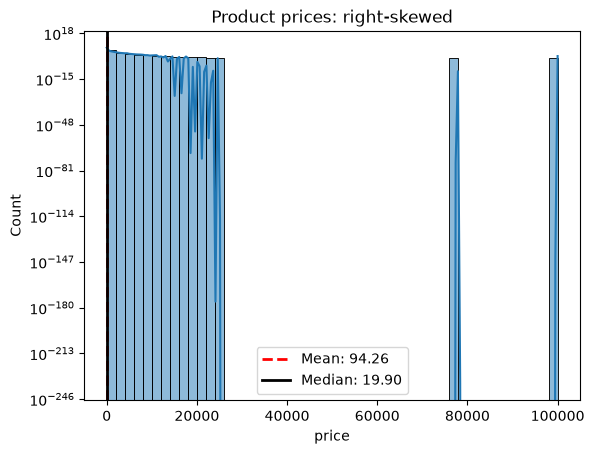

In [10]:
#Histogram:
ax = sns.histplot(df["price"], bins=50, kde=True)
ax.axvline(price_mean, color="red", linestyle="--",
           linewidth=2, label=f"Mean: {price_mean:.2f}")

ax.axvline(price_median, color="black", linestyle="-",
           linewidth=2, label=f"Median: {price_median:.2f}")

#ax.axvline(df["price"].mean(), color="red", linestyle="--", label="mean")
#ax.axvline(df["price"].median(), color="black", label="median")
ax.legend()
ax.set_yscale("log") # Using logscale for better visualisation
ax.set_title("Product prices: right-skewed")
plt.show()

# 

Is there a specific price range where most products fall? 
Hard to see because of very discrepant counts. Using a logscale helps.
The mean and the median are squeezed at the beginning of the histogram
and can'be seen. Plotting only prices without outliers:


In [11]:
filter = (df["price"] >= price_q1-1.5*price_iqr ) & (df["price"] <= price_q3 + 1.5*price_iqr)
price_clean = df.loc[filter]


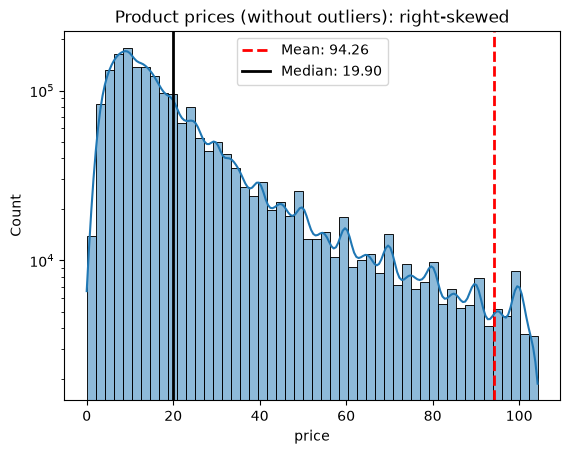

In [14]:
ax = sns.histplot(price_clean["price"], bins=50, kde=True)
ax.axvline(price_mean, color="red", linestyle="--",
           linewidth=2, label=f"Mean: {price_mean:.2f}")

ax.axvline(price_median, color="black", linestyle="-",
           linewidth=2, label=f"Median: {price_median:.2f}")

#ax.axvline(df["price"].mean(), color="red", linestyle="--", label="mean")
#ax.axvline(df["price"].median(), color="black", label="median")
ax.legend()
ax.set_yscale("log") # Using logscale for better visualisation
ax.set_title("Product prices (without outliers): right-skewed")
plt.show()

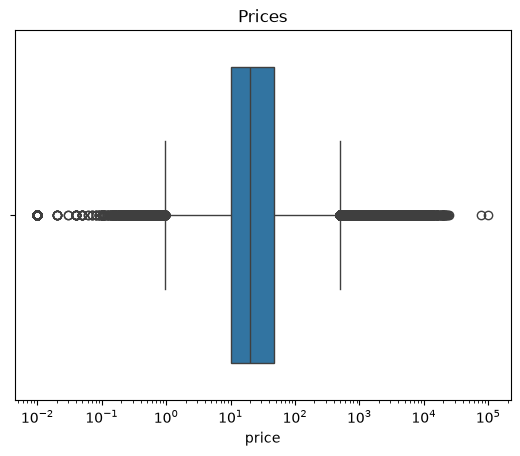

In [ ]:
# The boxplot

fig = sns.boxplot(x=df["price"], log_scale=True).set_title("Prices")
plt.show()

# Again, had to use logscale to better visualize it. But we can see that most prices are in a narrow range,
# but there are a lot of outliers, above and below

Part 3: Unpacking Product Ratings

Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

 


    Shape of the Distribution:
        Calculate the skewness and kurtosis for the rating column.
        Are the ratings normally distributed, or do they lean towards higher or lower values?

 

   Measures of Centrality:
        Calculate the mean, median, and mode for the rating of products.
        How do customers generally rate products? Is there a common trend?

In [116]:
df["stars"].describe()

stars_mean = df["stars"].mean()
stars_median = df["stars"].median()
stars_counts = df["stars"].value_counts()
stars_counts.index[0]
stars_mode = df["stars"].mode().iloc[0]
print( f"mean:{stars_mean}, mode:{stars_mode}, median:{stars_median}")

review_counts = df["stars"].value_counts()
print(review_counts[:10])

print("It seems that most customers give no rating(zero stars) to the products. If they rate, they give mostly good ratings to the products")


mean:2.0318699606162114, mode:0.0, median:0.0
stars
0.0    1174420
4.5     128640
4.4     115743
4.6     114933
5.0     110015
4.3      96599
4.7      79370
4.2      75275
4.0      58503
4.1      56698
Name: count, dtype: int64
It seems that most customers give no rating(zero stars) to the products. If they rate, they give mostly good ratings to the products



    Measures of Dispersion:
        Determine the variance, standard deviation, and interquartile range for product rating.
        Are the ratings consistent, or is there a wide variation in customer feedback?

In [ ]:

stars_std = df["stars"].std()
stars_min = df["stars"].min()
stars_max = df["stars"].max()
stars_q1 = df["stars"].quantile(q=0.25)
stars_q2 = df["stars"].quantile(q=0.5)
stars_q3 = df["stars"].quantile(q=0.75)
stars_iqr = stars_q3 - stars_q1
print( f"Std dev: {stars_std}, min-max: {stars_min}-{stars_max}, iqr:{stars_iqr}")
df["stars"].describe()

print ("The stars are by definition from 0 (no review) to 5 (best review) The mean is around 2 (middle range). \
The majority of the customers do not rate, it pulls the mean and the median down. \
The ratings are otherwise very spread, mostly between 0 and 4.4.")


Std dev: 2.185497413223386, min-max: 0.0-5.0, iqr:4.4
The stars are by definition from 0 (no review) to 5 (best review) The mean is around 2 (middle range). The majority of the customers do not rate, it pulls the mean and the median down. The ratings are otherwise very spread, mostly between 0 and 4.4.


   Visualizations:
        Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?


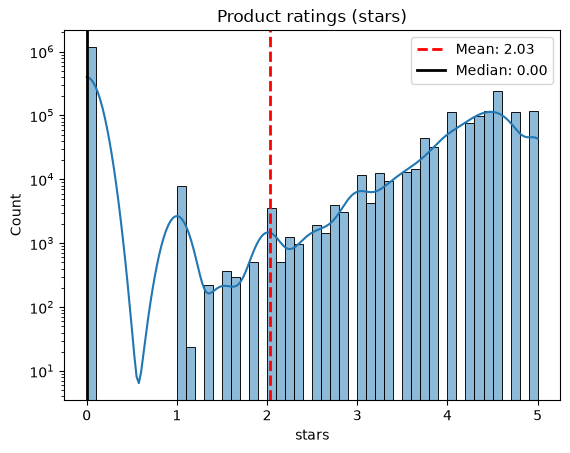

In [ ]:
ax = sns.histplot(df["stars"], bins=50, kde=True)
ax.axvline(stars_mean, color="red", linestyle="--",
           linewidth=2, label=f"Mean: {stars_mean:.2f}")

ax.axvline(stars_median, color="black", linestyle="-",
           linewidth=2, label=f"Median: {stars_median:.2f}")

#ax.axvline(df["stars"].mean(), color="red", linestyle="--", label="mean")
#ax.axvline(df["stars"].median(), color="black", label="median")
ax.legend()
ax.set_yscale("log") # Using logscale for better visualisation
ax.set_title("Product ratings (stars)")
plt.show()




We saw that most of the customers did not rate. Now I want to compute the statistics only for the  products being rated.


In [128]:
 
star_rates= df.loc[df["stars"] != 0, "stars"]

stars_mean = star_rates.mean()
stars_median = star_rates.median()
stars_counts = star_rates.value_counts()
stars_mode = star_rates.mode().iloc[0]
print( f"mean:{stars_mean}, mode:{stars_mode}, median:{stars_median}")
stars_std = star_rates.std()
stars_min = star_rates.min()
stars_max = star_rates.max()
stars_q1 = star_rates.quantile(q=0.25)
stars_q2 = star_rates.quantile(q=0.5)
stars_q3 = star_rates.quantile(q=0.75)
stars_iqr = stars_q3 - stars_q1
print( f"Std dev: {stars_std}, min-max: {stars_min}-{stars_max}, iqr:{stars_iqr}")
df["stars"].describe()

mean:4.30814453955941, mode:4.5, median:4.4
Std dev: 0.5663970033306724, min-max: 1.0-5.0, iqr:0.5


count    2.222742e+06
mean     2.031870e+00
std      2.185497e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      4.400000e+00
max      5.000000e+00
Name: stars, dtype: float64

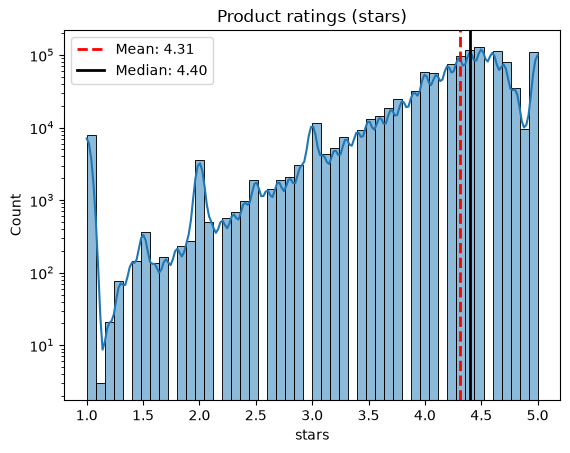

In [129]:
ax = sns.histplot(star_rates, bins=50, kde=True)
ax.axvline(stars_mean, color="red", linestyle="--",
           linewidth=2, label=f"Mean: {stars_mean:.2f}")

ax.axvline(stars_median, color="black", linestyle="-",
           linewidth=2, label=f"Median: {stars_median:.2f}")
ax.legend()
ax.set_yscale("log") # Using logscale for better visualisation
ax.set_title("Product ratings (stars)")
plt.show()

Most customers do not rate. If customers rate, they tend to rate 1 star if they are not satisfied (less common), or 4-5 if they are satisfied.